In [4]:
# Imports and config
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, f1_score, balanced_accuracy_score, make_scorer

import sys
sys.path.append("..")  # Ensure parent dir is in path
from data.data_loader import DataLoader
from data.data_configs import SUBJECTS

### Load Data

In [5]:
# Load features using DataLoader
X, y, feature_names, subject_ids = DataLoader.load_features(SUBJECTS, mode="advanced")
print(f"Loaded features for {len(subject_ids)} samples from {len(SUBJECTS)} subject(s)")
print(f"X shape: {X.shape}, y shape: {y.shape}")

Loaded features for 33008 samples from 13 subject(s)
X shape: (33008, 240), y shape: (33008,)


In [6]:
pd.Series(y).value_counts()

True     18290
False    14718
Name: count, dtype: int64

In [7]:
print("Label distribution (%):")
print(pd.Series(y).value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

Label distribution (%):
True     55.41%
False    44.59%
Name: proportion, dtype: object


In [8]:
# %% Clean data - handle NaNs
df = pd.DataFrame(X, columns=feature_names)
nan_counts = df.isna().sum()
print(f"\nFeatures with NaNs: {(nan_counts > 0).sum()}")

# Remove features with >50% NaN
high_nan = nan_counts[nan_counts > len(df) * 0.5].index.tolist()
feature_names_clean = [f for f in feature_names if f not in high_nan]
print(f"Features after cleaning: {len(feature_names_clean)}")

# Impute remaining NaNs
X_clean = df[feature_names_clean].values
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X_clean)


Features with NaNs: 0
Features after cleaning: 240


In [9]:
# %% Correlation with label
temp_df = pd.DataFrame(X_imputed, columns=feature_names_clean)
temp_df['label'] = y
label_corr = temp_df.corr()['label'].drop('label').sort_values(ascending=False)

print(f"\nTop 5 correlated features:\n{label_corr.head()}")


Top 5 correlated features:
F7_kurtosis        0.043076
P7_kurtosis        0.032691
Pz_dfa             0.030986
FC6_delta_power    0.029375
P3_kurtosis        0.028621
Name: label, dtype: float64


In [10]:
np.unique(subject_ids)

array(['P01', 'P07', 'P09', 'P10', 'P16', 'P17', 'P20', 'P21', 'P27',
       'P28', 'P30', 'P34', 'P38'], dtype='<U3')

In [11]:
import numpy as np
from sklearn.preprocessing import StandardScaler

subject_ids = np.array(subject_ids)  # convert list of strings to array
X_scaled = np.zeros_like(X_imputed)

for subj in np.unique(subject_ids):
    subj_idx = np.where(subject_ids == subj)[0]  # now this works
    scaler = StandardScaler()
    X_scaled[subj_idx] = scaler.fit_transform(X_imputed[subj_idx])

In [12]:
X_scaled.shape

(33008, 240)

In [13]:
# -------------------------
# Model
# -------------------------
model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')

# -------------------------
# Scorers
# -------------------------
f1_macro_scorer = make_scorer(f1_score, average='macro')
balanced_acc_scorer = make_scorer(balanced_accuracy_score)


=== Stratified K-Fold CV ===
Fold 1: Accuracy=0.7258, Macro-F1=0.7138, Balanced Acc=0.7120
Fold 2: Accuracy=0.7152, Macro-F1=0.7040, Balanced Acc=0.7024
Fold 3: Accuracy=0.7136, Macro-F1=0.7020, Balanced Acc=0.7004
Fold 4: Accuracy=0.7250, Macro-F1=0.7121, Balanced Acc=0.7104
Fold 5: Accuracy=0.7225, Macro-F1=0.7085, Balanced Acc=0.7071

Overall Macro-F1: 0.7081
Overall Balanced Accuracy: 0.7065


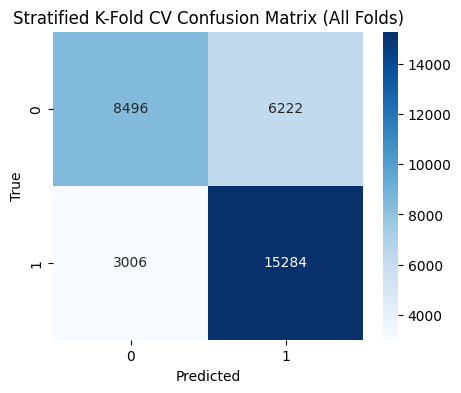

In [14]:
# -------------------------
# 1. Stratified K-Fold CV with per-fold accuracy
# -------------------------
print("=== Stratified K-Fold CV ===")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y_true_all, y_pred_all = [], []

for fold, (train_idx, test_idx) in enumerate(skf.split(X_scaled, y), 1):
    model.fit(X_scaled[train_idx], y[train_idx])
    y_pred = model.predict(X_scaled[test_idx])
    
    # Store for overall metrics
    y_true_all.append(y[test_idx])
    y_pred_all.append(y_pred)
    
    # Compute fold metrics
    acc = accuracy_score(y[test_idx], y_pred)
    f1 = f1_score(y[test_idx], y_pred, average='macro')
    bal_acc = balanced_accuracy_score(y[test_idx], y_pred)
    print(f"Fold {fold}: Accuracy={acc:.4f}, Macro-F1={f1:.4f}, Balanced Acc={bal_acc:.4f}")

# Aggregate over all folds
y_true_all = np.concatenate(y_true_all)
y_pred_all = np.concatenate(y_pred_all)

f1_macro = f1_score(y_true_all, y_pred_all, average='macro')
bal_acc = balanced_accuracy_score(y_true_all, y_pred_all)
print(f"\nOverall Macro-F1: {f1_macro:.4f}")
print(f"Overall Balanced Accuracy: {bal_acc:.4f}")

# Confusion Matrix for all folds combined
cm = confusion_matrix(y_true_all, y_pred_all)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Stratified K-Fold CV Confusion Matrix (All Folds)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()


=== Grouped K-Fold CV (Subject-Level, 5 Splits) ===
Fold 1 | Subjects: ['P09' 'P21' 'P28'] | Accuracy=0.5175, Macro-F1=0.4445, Balanced Acc=0.4992
Fold 2 | Subjects: ['P01' 'P17'] | Accuracy=0.5243, Macro-F1=0.4978, Balanced Acc=0.5049
Fold 3 | Subjects: ['P16' 'P20' 'P38'] | Accuracy=0.5481, Macro-F1=0.4585, Balanced Acc=0.5022
Fold 4 | Subjects: ['P07' 'P27' 'P30'] | Accuracy=0.5342, Macro-F1=0.4968, Balanced Acc=0.5064
Fold 5 | Subjects: ['P10' 'P34'] | Accuracy=0.5287, Macro-F1=0.4697, Balanced Acc=0.5000

Overall Macro-F1: 0.4754
Overall Balanced Accuracy: 0.5017


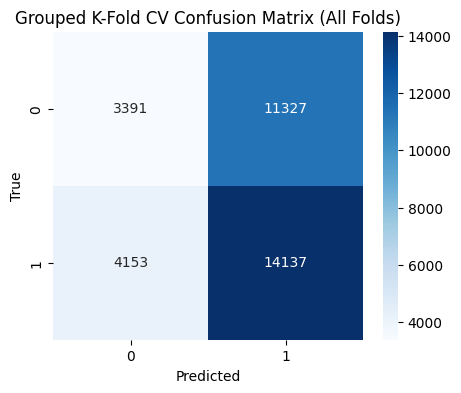

In [15]:

# Make sure subject_ids is a NumPy array
subject_ids = np.array(subject_ids)

print("=== Grouped K-Fold CV (Subject-Level, 5 Splits) ===")
gkf = GroupKFold(n_splits=5)
y_true_all, y_pred_all = [], []

for fold, (train_idx, test_idx) in enumerate(gkf.split(X_scaled, y, groups=subject_ids), 1):
    model.fit(X_scaled[train_idx], y[train_idx])
    y_pred = model.predict(X_scaled[test_idx])
    
    # Store for overall metrics
    y_true_all.append(y[test_idx])
    y_pred_all.append(y_pred)
    
    # Fold-level metrics
    acc = accuracy_score(y[test_idx], y_pred)
    f1 = f1_score(y[test_idx], y_pred, average='macro')
    bal_acc = balanced_accuracy_score(y[test_idx], y_pred)
    subjects_in_fold = np.unique(subject_ids[test_idx])
    print(f"Fold {fold} | Subjects: {subjects_in_fold} | Accuracy={acc:.4f}, Macro-F1={f1:.4f}, Balanced Acc={bal_acc:.4f}")

# Aggregate over all folds
y_true_all = np.concatenate(y_true_all)
y_pred_all = np.concatenate(y_pred_all)

print(f"\nOverall Macro-F1: {f1_score(y_true_all, y_pred_all, average='macro'):.4f}")
print(f"Overall Balanced Accuracy: {balanced_accuracy_score(y_true_all, y_pred_all):.4f}")

# Confusion Matrix for all folds combined
cm = confusion_matrix(y_true_all, y_pred_all)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Grouped K-Fold CV Confusion Matrix (All Folds)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()
